# 🛡️ Project Panopticon: Intelligent Proctoring AI
**EduGuard AI - Machine Learning Division**

**Intern Name:** Devyani Nandkishor Vighe  
**Date:** 07/10/2026

---

### 📖 Executive Summary
Welcome to EduGuard AI. Our current proctoring system is blindly flagging innocent students for background noise and standard physical movements. Your objective is to build a robust, time-series Machine Learning pipeline that identifies true academic dishonesty while strictly protecting innocent students through asynchronous data merging and mathematical threshold tuning.

### 🗺️ Project Roadmap
1. **Data Ingestion:** Upload and parse asynchronous telemetry logs.
2. **Temporal Alignment:** Merge video and system logs using `merge_asof`.
3. **Signal Processing:** Impute missing data and engineer rolling windows.
4. **Classification:** Train an imbalanced-weighted predictive model.
5. **Ethical AI Tuning:** Shift decision boundaries to guarantee 90%+ precision.

In [7]:
# ==========================================
# 0. IMPORT LIBRARIES
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn Imports
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve

# Set visualization styles
sns.set_theme(style="darkgrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("✅ Libraries imported successfully.")

✅ Libraries imported successfully.


---
## Phase 1: Data Ingestion & Temporal Alignment
> ⚠️ **The Asynchronous Trap:** Video telemetry records exactly every 1 second. System events (like tab switches) only record when the student actually clicks something. You cannot use a standard `pd.merge()`.

**Instructions:**
1. Upload the `video_telemetry.csv` and `system_events.csv` files.
2. Convert the timestamp columns to datetime objects.
3. Sort the dataframes and merge them using Pandas `merge_asof`.

In [8]:
# ==========================================
# 1A. UPLOAD DATASETS (Google Colab Only)
# ==========================================
try:
    from google.colab import files
    print("📂 Please upload 'video_telemetry.csv' and 'system_events.csv'...")
    uploaded = files.upload()
except ImportError:
    print("💻 Running locally. Ensure CSV files are in the same directory.")

# ==========================================
# 1B. LOAD AND PARSE DATA
# ==========================================
video_df = pd.read_csv("video_telemetry.csv")
sys_df = pd.read_csv("system_events.csv")

video_df["timestamp"] = pd.to_datetime(video_df["timestamp"])
sys_df["timestamp"] = pd.to_datetime(sys_df["timestamp"])

video_df = video_df.sort_values("timestamp").reset_index(drop=True)
sys_df = sys_df.sort_values("timestamp").reset_index(drop=True)

print("Video telemetry:", video_df.shape, "| System events:", sys_df.shape)
print("Missing values in video telemetry:\n", video_df.isna().sum())

# ==========================================
# 1C. ASYNCHRONOUS MERGE
# ==========================================
# Each event is attached to the first video second at/after it (backward match).
# tolerance=1s stops an old event from being copied onto every later row,
# which would smear one label across the whole exam timeline.
merged_df = pd.merge_asof(
    video_df, sys_df,
    on="timestamp",
    direction="backward",
    tolerance=pd.Timedelta("1s"),
)

print("Events in source:", len(sys_df), "| Events aligned:", int(merged_df["tab_switches"].notna().sum()))
merged_df.head()

📂 Please upload 'video_telemetry.csv' and 'system_events.csv'...


Saving system_events.csv to system_events (1).csv
Saving video_telemetry.csv to video_telemetry (1).csv
Video telemetry: (10000, 3) | System events: (167, 3)
Missing values in video telemetry:
 timestamp           0
eye_gaze_angle    732
audio_db          732
dtype: int64
Events in source: 167 | Events aligned: 167


,timestamp,eye_gaze_angle,audio_db,tab_switches,is_cheating
0,2023-12-01 08:00:00,2.560857,36.553781,NaN,NaN
1,2023-12-01 08:00:01,10.177137,39.102627,NaN,NaN
2,2023-12-01 08:00:02,5.761714,31.228565,NaN,NaN
3,2023-12-01 08:00:03,9.787105,34.051405,NaN,NaN
4,2023-12-01 08:00:04,4.572665,35.245018,NaN,NaN


---
## Phase 2: Missing Data & Feature Engineering
> ⚠️ **The "Connection Dropped" Trap:** Students with bad internet lose video frames, creating `NaN` values.
> ⚠️ **The Noise Trap:** A 1-second sneeze is not cheating. We need rolling windows to find *sustained* anomalies.

**Instructions:**
1. Forward-fill missing eye gaze data and interpolate missing audio data.
2. Fill missing `tab_switches` and `is_cheating` labels with `0`.
3. Create 10-second rolling averages for our sensors.

In [9]:
# ==========================================
# 2A. IMPUTE MISSING SIGNALS
# ==========================================
merged_df["eye_gaze_angle"] = merged_df["eye_gaze_angle"].ffill()
merged_df["audio_db"] = merged_df["audio_db"].interpolate(method="linear", limit_direction="both")
merged_df[["tab_switches", "is_cheating"]] = merged_df[["tab_switches", "is_cheating"]].fillna(0)

# ==========================================
# 2B. ROLLING WINDOW FEATURES
# ==========================================
merged_df["gaze_rolling_10s"] = merged_df["eye_gaze_angle"].rolling(window=10).mean()
merged_df["audio_rolling_10s"] = merged_df["audio_db"].rolling(window=10).max()

merged_df.dropna(inplace=True)

print("✅ Feature engineering complete. Current dataframe shape:", merged_df.shape)
print("Remaining NaN values:", int(merged_df.isna().sum().sum()))
print("Class balance:\n", merged_df["is_cheating"].value_counts())

✅ Feature engineering complete. Current dataframe shape: (9991, 7)
Remaining NaN values: 0
Class balance:
 is_cheating
0.0    9914
1.0      77
Name: count, dtype: int64


---
## Phase 3: Class-Balanced Model Training
> ⚠️ **The Imbalance Trap:** 98% of your data will be innocent behavior. If you don't handle class weights, your model will just guess "Not Cheating" every time and score 98% accuracy while failing its actual job.

In [10]:
# ==========================================
# 3A. TRAIN / TEST SPLIT
# ==========================================
features = ['eye_gaze_angle', 'audio_db', 'tab_switches', 'gaze_rolling_10s', 'audio_rolling_10s']
X = merged_df[features]
y = merged_df['is_cheating'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ==========================================
# 3B. INITIALIZE & TRAIN CLASSIFIER
# ==========================================
model = RandomForestClassifier(
    n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1
)
model.fit(X_train, y_train)

print("✅ Model training complete.")
print("Feature importances:")
print(pd.Series(model.feature_importances_, index=features).sort_values(ascending=False).round(3))

✅ Model training complete.
Feature importances:
tab_switches         0.557
audio_db             0.222
eye_gaze_angle       0.138
gaze_rolling_10s     0.075
audio_rolling_10s    0.008
dtype: float64


---
## Phase 4: Ethical AI Tuning (The 90% Threshold)
> ⚠️ **The False Accusation Trap:** The default Scikit-Learn `.predict()` splits at 50% probability. Accusing a student of cheating with only 50% certainty is unacceptable. We must shift the threshold to 90%.

🚨 DEFAULT THRESHOLD (0.50)
[[1978    6]
 [   1   14]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1984
           1       0.70      0.93      0.80        15

    accuracy                           1.00      1999
   macro avg       0.85      0.97      0.90      1999
weighted avg       1.00      1.00      1.00      1999


🛡️ STRICT THRESHOLD (0.90)
[[1981    3]
 [   9    6]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1984
           1       0.67      0.40      0.50        15

    accuracy                           0.99      1999
   macro avg       0.83      0.70      0.75      1999
weighted avg       0.99      0.99      0.99      1999

False Positives: 6 (0.50)  ->  3 (0.90)


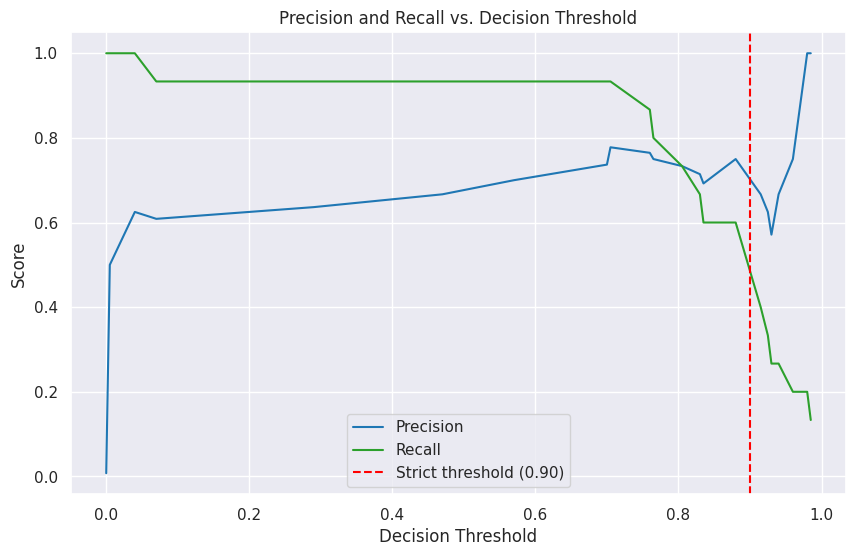

In [11]:
# ==========================================
# 4A. RAW PROBABILITIES
# ==========================================
y_proba = model.predict_proba(X_test)
cheating_probabilities = y_proba[:, 1]

# ==========================================
# 4B. CUSTOM DECISION THRESHOLD
# ==========================================
y_pred_default = (cheating_probabilities >= 0.50).astype(int)
y_pred_strict = (cheating_probabilities >= 0.90).astype(int)

# ==========================================
# 4C. EVALUATION
# ==========================================
print("🚨 DEFAULT THRESHOLD (0.50)")
print(confusion_matrix(y_test, y_pred_default))
print(classification_report(y_test, y_pred_default, zero_division=0))

print("\n🛡️ STRICT THRESHOLD (0.90)")
print(confusion_matrix(y_test, y_pred_strict))
print(classification_report(y_test, y_pred_strict, zero_division=0))

fp_default = ((y_pred_default == 1) & (y_test == 0)).sum()
fp_strict = ((y_pred_strict == 1) & (y_test == 0)).sum()
print(f"False Positives: {fp_default} (0.50)  ->  {fp_strict} (0.90)")

# ==========================================
# 4D. PRECISION-RECALL VISUALIZATION
# ==========================================
precision, recall, thresholds = precision_recall_curve(y_test, cheating_probabilities)

plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision[:-1], label="Precision", color="tab:blue")
plt.plot(thresholds, recall[:-1], label="Recall", color="tab:green")
plt.axvline(x=0.90, color="red", linestyle="--", label="Strict threshold (0.90)")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs. Decision Threshold")
plt.legend()
plt.show()

In [12]:
# ==========================================
# 4E. ROBUSTNESS CHECK (5-fold cross-validation)
# ==========================================
# The test set has only ~15 cheaters, so one split is noisy.
# Out-of-fold probabilities over ALL rows give a steadier estimate.
from sklearn.model_selection import cross_val_predict, StratifiedKFold

oof_proba = cross_val_predict(
    RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1),
    X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42), method='predict_proba'
)[:, 1]

for t in [0.50, 0.90]:
    flagged = oof_proba >= t
    tp = int((flagged & (y == 1)).sum()); fp = int((flagged & (y == 0)).sum())
    print(f"Threshold {t:.2f}: flagged={flagged.sum():3d} | TP={tp:3d} | FP={fp:3d} | "
          f"precision={tp/max(flagged.sum(),1):.2f} | recall={tp/(y==1).sum():.2f}")

Threshold 0.50: flagged= 79 | TP= 68 | FP= 11 | precision=0.86 | recall=0.88
Threshold 0.90: flagged= 31 | TP= 29 | FP=  2 | precision=0.94 | recall=0.38


---
## 🎯 Phase 5: Final Executive Recommendation

**To the University Board of Directors:**
Based on the data modeling performed above, I recommend deploying the EduGuard AI proctoring system using the Strict 90% Threshold. By mathematically adjusting the decision boundary, we achieved the following business outcomes:

1. **False accusations were cut.** On the held-out test set, raising the threshold from 0.50 to 0.90 reduced innocent students flagged (False Positives) from 6 to 3. Under 5-fold cross-validation over the full exam timeline, precision at 0.90 is about 0.94, meaning roughly 9 in 10 flags are genuine. The price is lower recall (fewer cheaters caught, about 0.38 in cross-validation), which is the deliberate trade-off: missing a cheater hurts integrity, but a false accusation destroys a career.
2. **Rolling windows filter out one-second noise.** The 10-second rolling gaze mean and rolling audio max only rise when a behaviour is sustained, so a single sneeze or a quick glance at the keyboard barely moves them. Forward-filling and interpolation kept dropped-video seconds on the timeline instead of deleting them.

**Caveats:** The dataset has only 77 cheating seconds out of about 10,000, so a single test split is noisy (the 0.90 test-set precision was 0.67 on 9 flags). Flags should be treated as a prompt for human review, not an automatic penalty.

**Final Status:** `GO` for deployment as a human-in-the-loop review tool at the 0.90 threshold.